# Packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import re
import pyarrow
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import seaborn as sns
import scipy.stats as stats
import plotly.express as px
from datetime import date
from river.drift import ADWIN
from matplotlib.colors import ListedColormap

# Read data

In [2]:
features_df = pd.read_parquet(r"..\data\features\features.parquet", engine="pyarrow")

In [3]:
# Mobile mean with a window of one hour
hours = 1
# Apply filters to the time series of the features
features_df = features_df[(features_df['energy']>=0)&(features_df['kurtosis']<2500)&(features_df['frequency_index']>=-3)&(features_df['entropy']>=0)&(features_df['entropy']<15000)]
# Calculate moving average for all features
# Apply logarithmic transformation to energy and kurtosis variables
features_df['energy_mobile_mean'] = np.log10(features_df['energy'].rolling(window=11*hours, center=False).mean())
features_df['kurtosis_mobile_mean'] = np.log10(features_df['kurtosis'].rolling(window=11*hours, center=False).mean())
features_df['frequency_index_mobile_mean'] = features_df['frequency_index'].rolling(window=11*hours, center=False).mean()
features_df['entropy_mobile_mean'] = features_df['entropy'].rolling(window=11*hours, center=False).mean()
features_df['energy'] = np.log10(features_df['energy'])
features_df['kurtosis'] = np.log10(features_df['kurtosis'])

### Training Set

In [4]:
# Select just one month of data
features_df_1_month = features_df[features_df['timestamp']<"2022-02-01"]
# Filter the first eleven observations with NAs values
features_df_1_month = features_df_1_month.dropna(subset=['energy_mobile_mean'])

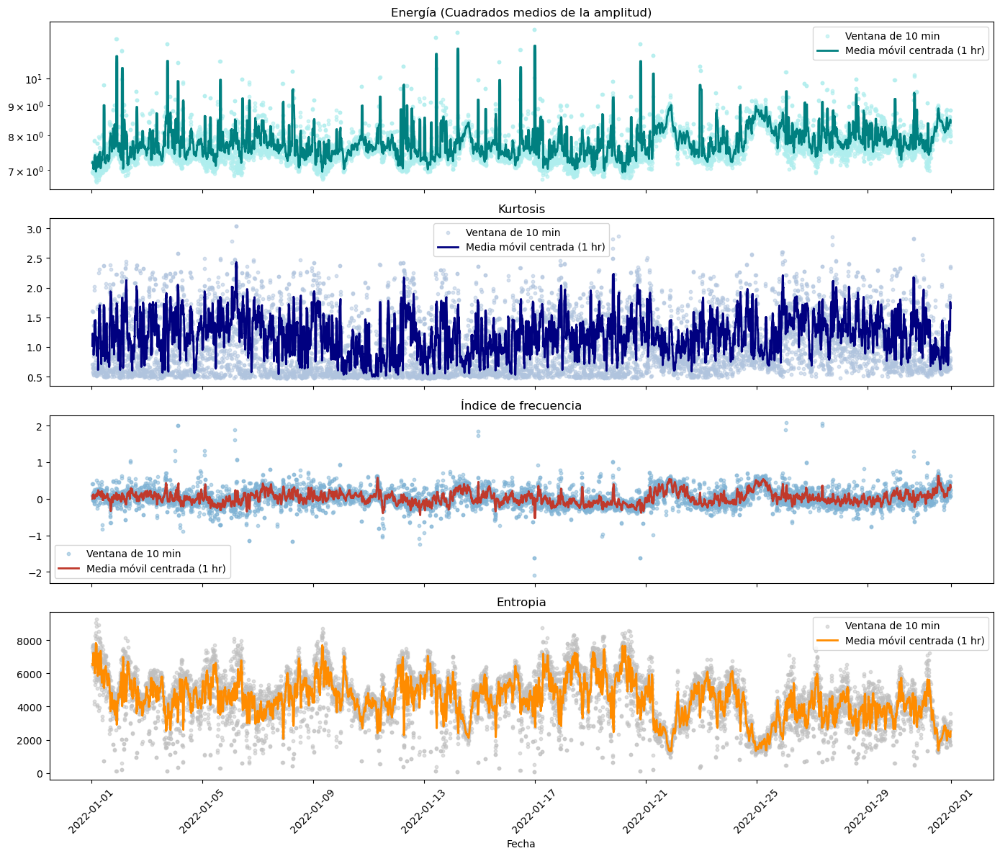

In [5]:
# Generate the plot
fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(14, 12), sharex=True)
axes[0].scatter(features_df_1_month['timestamp'], features_df_1_month['energy'], color='paleturquoise', s=10, alpha=0.6, label="Ventana de 10 min")
axes[0].plot(features_df_1_month['timestamp'], features_df_1_month['energy_mobile_mean'], color='teal', linewidth=2, label='Media móvil centrada (1 hr)')
axes[0].set_yscale('log')
axes[0].set_title('Energía (Cuadrados medios de la amplitud)')
axes[0].legend(loc='best')

axes[1].scatter(features_df_1_month['timestamp'], features_df_1_month['kurtosis'], color='lightsteelblue', s=10, alpha=0.5, label = "Ventana de 10 min")
axes[1].plot(features_df_1_month['timestamp'], features_df_1_month['kurtosis_mobile_mean'], color='navy', alpha = 1,linewidth=2, label='Media móvil centrada (1 hr)')
axes[1].set_title('Kurtosis')
axes[1].legend(loc='best')

axes[2].scatter(features_df_1_month['timestamp'], features_df_1_month['frequency_index'], color='#7FB3D5', s=10, alpha=0.5, label = "Ventana de 10 min")
axes[2].plot(features_df_1_month['timestamp'], features_df_1_month['frequency_index_mobile_mean'], color='#C0392B', alpha = 1,linewidth=2, label='Media móvil centrada (1 hr)')
axes[2].set_title('Índice de frecuencia')
axes[2].legend(loc='best')

axes[3].scatter(features_df_1_month['timestamp'], features_df_1_month['entropy'], color='silver', s=10, alpha=0.5, label = "Ventana de 10 min")
axes[3].plot(features_df_1_month['timestamp'], features_df_1_month['entropy_mobile_mean'], color='darkorange', alpha = 1,linewidth=2, label='Media móvil centrada (1 hr)')
axes[3].set_title('Entropia')
axes[3].set_xlabel('Fecha')
axes[3].legend(loc='best')

plt.xticks(rotation=45)
plt.tight_layout()

In [6]:
# Take descriptive variables
variables = ["energy_mobile_mean",	"kurtosis_mobile_mean", "frequency_index_mobile_mean", "entropy_mobile_mean"]
X = features_df_1_month[["energy_mobile_mean",	"kurtosis_mobile_mean",	
                         "frequency_index_mobile_mean", "entropy_mobile_mean"]].to_numpy()


##### Preproccesing

In [7]:
# Scale variables
scaler = StandardScaler().fit(X)
X = scaler.transform(X)

Dimensionality Reduction:
PCA

In [8]:
# Create a PCA object and train it
pca = PCA(n_components=3).fit(X)
# Transform the data to the new reducted space
Z = pca.transform(X)

In [9]:
# Report PCA summary
pcaSummary = pd.DataFrame({'Standard deviation': np.sqrt(pca.explained_variance_),
                           'Proportion of variance': pca.explained_variance_ratio_,
                           'Cumulative variance': np.cumsum(pca.explained_variance_ratio_)})

pcaSummary = pcaSummary.transpose()
pcaSummary.columns = ['PC'+str(ind) for ind in range(1, 4)]
pcaSummary.round(3)

,PC1,PC2,PC3
Standard deviation,1.443,1.074,0.728
Proportion of variance,0.520,0.288,0.133
Cumulative variance,0.520,0.809,0.941


In [22]:
# See the weights for each PC
pcaComponents = pd.DataFrame(pca.components_.transpose(),
                             columns=['PC'+str(ind) for ind in range(1, 4)],
                             index= variables)
pcaComponents

,PC1,PC2,PC3
energy_mobile_mean,-0.599894,0.238637,-0.404539
kurtosis_mobile_mean,-0.295610,0.744349,0.566410
frequency_index_mobile_mean,-0.414479,-0.594248,0.646543
entropy_mobile_mean,0.617211,0.189385,0.312267


### Clustering

In [10]:
km_model = KMeans(n_clusters=3, random_state=9972, n_init=10).fit(Z)

c:\Users\javie\miniconda3\envs\estancia_popocatepetl\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\javie\miniconda3\envs\estancia_popocatepetl\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\javie\miniconda3\envs\estancia_popocatepetl\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\javie\miniconda3\envs\estancia_popocatepetl\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:

In [11]:
# Create a dataframe with the clustering data
clustering_data = features_df_1_month[
    [   
        'timestamp',
        'energy_mobile_mean',
        'kurtosis_mobile_mean',
        'frequency_index_mobile_mean',
        'entropy_mobile_mean'
    ]
].copy()
clustering_data['labels'] = km_model.labels_

### Groups Distribution

In [12]:
clustering_data[['labels', 'energy_mobile_mean']].groupby('labels').count()

,energy_mobile_mean
labels,
0,2775
1,4649
2,1459


### Results Original Data

C:\Users\javie\AppData\Local\Temp\ipykernel_18332\2183430728.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


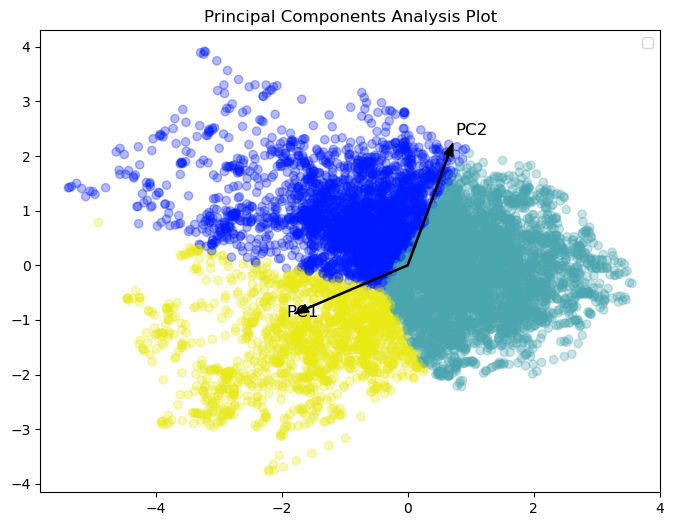

In [25]:
labels = km_model.labels_
custom_cmap = ListedColormap(["#001AFF", "#4aa5af", "#e9e913"])

plt.figure(figsize=(8, 6))
scatter = plt.scatter(Z[:, 0], Z[:, 1], c=labels, cmap=custom_cmap, alpha=0.3)
#plt.scatter(centroids[:, 0], centroids[:, 1], c='red', s=200, marker='+')
# Plot principal component axes
origin = np.mean(Z[:, :2], axis=0)
for i, (vec, var) in enumerate(zip(pca.components_[:2], pca.explained_variance_ratio_[:2])):
    plt.arrow(origin[0], origin[1], vec[0]*3, vec[1]*3, color='black', width=0.02, head_width=0.15, length_includes_head=True)
    plt.text(origin[0] + vec[0]*3.2, origin[1] + vec[1]*3.2, f'PC{i+1}', color='black', fontsize=12)
plt.title('Principal Components Analysis Plot')
plt.legend()
plt.show()

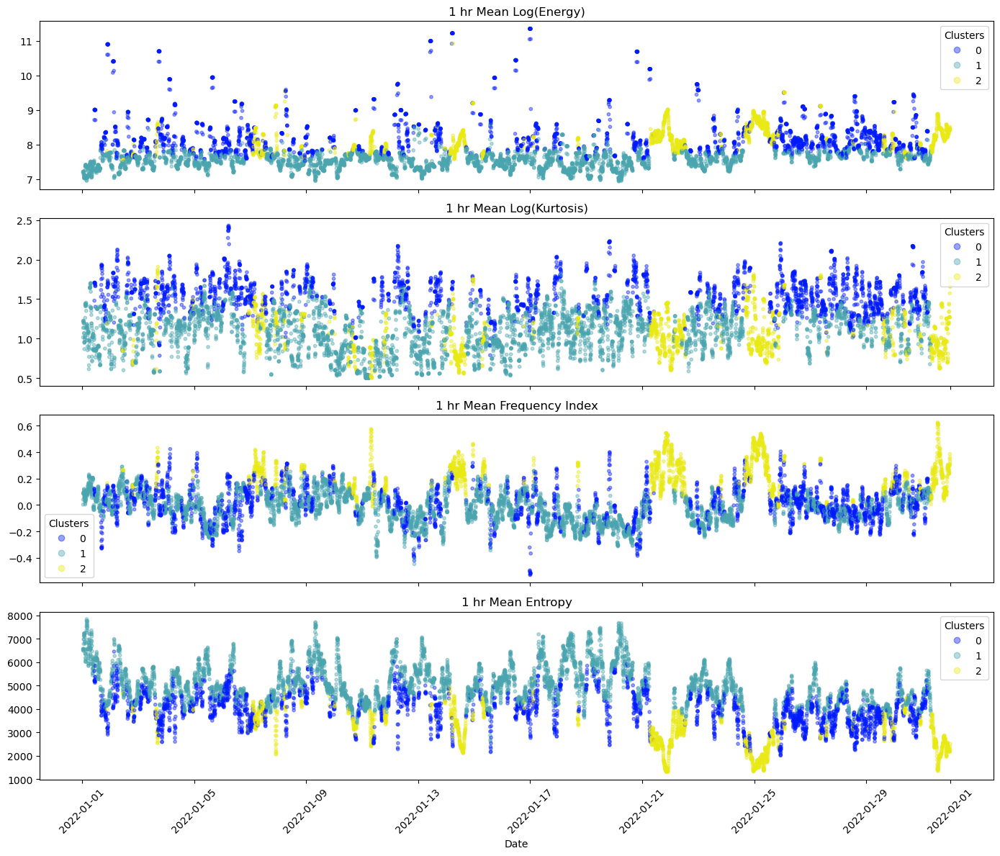

In [27]:
# Generate the plot
fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(14, 12), sharex=True)
scatter = axes[0].scatter(clustering_data['timestamp'], clustering_data['energy_mobile_mean'], c=clustering_data['labels'], cmap=custom_cmap, s=10, alpha=0.4)
axes[0].set_title('1 hr Mean Log(Energy)')
axes[0].legend(*scatter.legend_elements(), title="Clusters")

scatter = axes[1].scatter(clustering_data['timestamp'], clustering_data['kurtosis_mobile_mean'], c=clustering_data['labels'], cmap=custom_cmap, s=10, alpha=0.4)
axes[1].set_title('1 hr Mean Log(Kurtosis)')
axes[1].legend(*scatter.legend_elements(), title="Clusters")

scatter = axes[2].scatter(clustering_data['timestamp'], clustering_data['frequency_index_mobile_mean'], c=clustering_data['labels'], cmap=custom_cmap, s=10, alpha=0.4)
axes[2].set_title('1 hr Mean Frequency Index')
axes[2].legend(*scatter.legend_elements(), title="Clusters")

scatter = axes[3].scatter(clustering_data['timestamp'], clustering_data['entropy_mobile_mean'], c=clustering_data['labels'], cmap=custom_cmap, s=10, alpha=0.4)
axes[3].set_title('1 hr Mean Entropy')
axes[3].set_xlabel('Date')
axes[3].legend(*scatter.legend_elements(), title="Clusters")

plt.xticks(rotation=45)
plt.tight_layout()

In [16]:
clustering_data['day'] = pd.to_datetime(clustering_data['timestamp']).dt.date

In [17]:
clustering_data.head(10)

,timestamp,energy_mobile_mean,kurtosis_mobile_mean,frequency_index_mobile_mean,entropy_mobile_mean,labels,day
10,2022-01-01 00:55:00,7.189824,1.016756,0.002807,6566.963119,1,2022-01-01
11,2022-01-01 01:00:00,7.202035,1.135282,0.040282,6541.763823,1,2022-01-01
12,2022-01-01 01:05:00,7.217582,1.225977,0.087732,6484.417105,1,2022-01-01
13,2022-01-01 01:10:00,7.214921,1.221882,0.091360,6501.124913,1,2022-01-01
14,2022-01-01 01:15:00,7.209869,1.217271,0.082832,6542.602102,1,2022-01-01
15,2022-01-01 01:20:00,7.206780,1.214691,0.095824,6571.488959,1,2022-01-01
16,2022-01-01 01:25:00,7.166144,1.203743,0.087245,6777.034629,1,2022-01-01
17,2022-01-01 01:30:00,7.124996,1.192086,0.082709,6969.591579,1,2022-01-01
18,2022-01-01 01:35:00,7.126502,1.196224,0.100424,6970.901690,1,2022-01-01
19,2022-01-01 01:40:00,7.077612,1.138447,0.115834,7121.470076,1,2022-01-01


In [18]:
# Group by day and take the first mode
daily_predominant_df = (
    clustering_data.groupby('day')["labels"]
    .agg(lambda x: x.mode().iat[0])
    .reset_index(name="label")
)


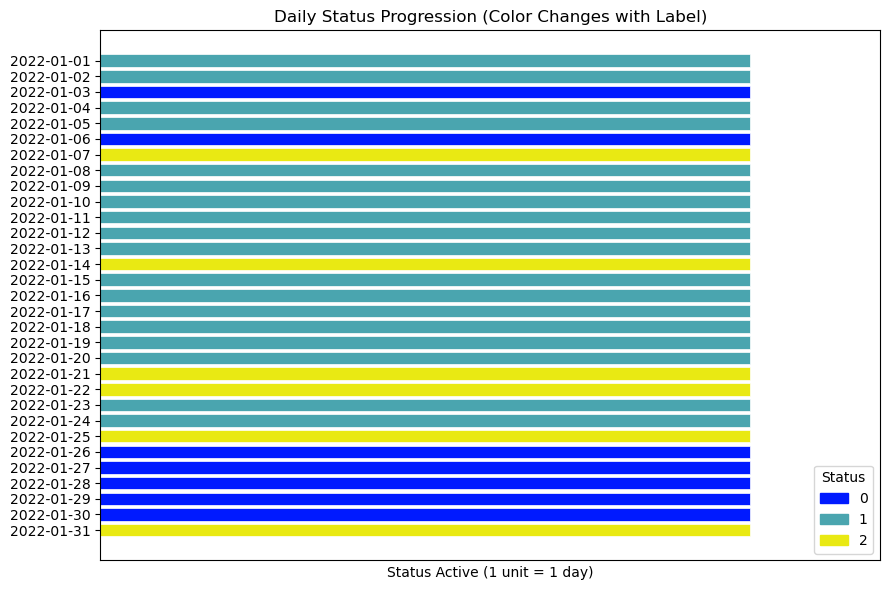

In [24]:
import matplotlib.patches as mpatches

palette = {0:"#001AFF", 1:"#4aa5af", 2:"#e9e913"}

# 2. Plot horizontal blocks (width = 1 day per row)
fig, ax = plt.subplots(figsize=(9, 6))

bar_colors = daily_predominant_df["label"].map(palette)

bar_colors.head()

ax.barh(
    y=daily_predominant_df["day"],
    width=1,  # Each day spans 1 unit
    color=bar_colors,
    edgecolor="white",
    linewidth=0.5,
    height=0.8,
)

# Formatting
ax.invert_yaxis()  # Day 1 starts at top
ax.set_yticks(daily_predominant_df["day"])
ax.set_yticklabels([f"{d}" for d in daily_predominant_df["day"]])
ax.set_xlabel("Status Active (1 unit = 1 day)")
ax.set_title("Daily Status Progression (Color Changes with Label)")
ax.set_xlim(0, 1.2)
ax.set_xticks([])  # Hide x-axis numbers

# 3. Add legend for unique labels
patches = [
    mpatches.Patch(color=color, label=name) for name, color in palette.items()
]
ax.legend(
    handles=patches,
    title="Status",
    loc="lower right",
    frameon=True,
)

plt.tight_layout()
plt.show()

### Identify Outliers

In [28]:
distances = km_model.transform(Z)
clustering_data['distance_to_centroid'] = [distances[i, label] for i, label in enumerate(km_model.labels_)]

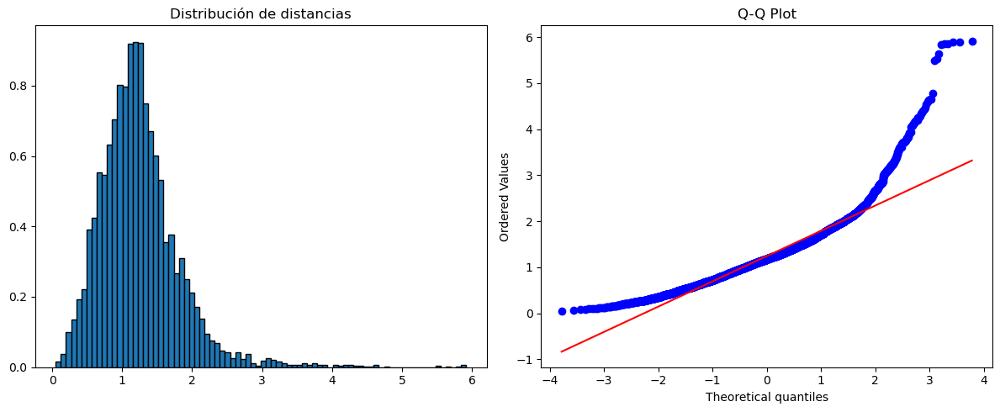

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Histogram
axes[0].hist(clustering_data['distance_to_centroid'], bins=80, density=True, edgecolor='black')
axes[0].set_title('Distribución de distancias')

# Q-Q plot
stats.probplot(clustering_data['distance_to_centroid'], plot=axes[1])
axes[1].set_title('Q-Q Plot')

plt.tight_layout()
plt.show()

In [30]:
# Clasificamos los valores observados como típicos y atípicos
clustering_data['outliers'] = clustering_data['distance_to_centroid'] > 5

In [31]:
# 
sum(clustering_data['outliers'])

9

### Next Months Forecast

In [32]:
features_df_pred = features_df[(features_df['timestamp']<"2025-01-01") & (features_df['timestamp']>="2022-02-01")]

clustering_data_pred = features_df_pred[
    [
        'energy_mobile_mean',
        'kurtosis_mobile_mean',
        'frequency_index_mobile_mean',
        'entropy_mobile_mean'
    ]
]

In [33]:
# Scale variables
X_pred = scaler.transform(clustering_data_pred)
# Transform the data to the new reducted space
Z_pred = pca.transform(X_pred)

c:\Users\javie\miniconda3\envs\estancia_popocatepetl\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [34]:
# Predict clusters for new data using the same centroids
labels_pred = km_model.predict(Z_pred)

### Outliers in New Data

In [35]:
# Add labels and timestamp to the new dataframe
clustering_data_pred['timestamp'] = features_df_pred['timestamp']
clustering_data_pred['labels'] = labels_pred

distances_pred = km_model.transform(Z_pred)



clustering_data_pred['distance_to_centroid'] = [distances_pred[i, label] for i, label in enumerate(labels_pred)]
clustering_data_pred['outliers'] = clustering_data_pred['distance_to_centroid'] > 5


In [36]:
# Concat the test data
clustering_data_all = pd.concat([clustering_data, clustering_data_pred], axis = 0)

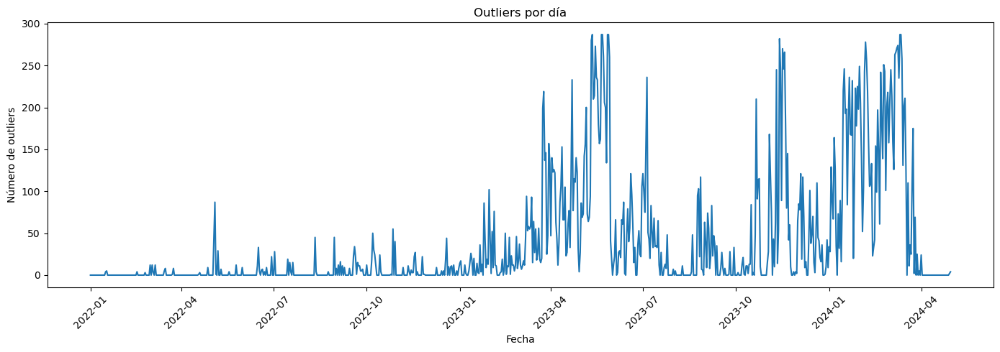

In [37]:
clustering_data_all['date'] = pd.to_datetime(clustering_data_all['timestamp']).dt.date

total_by_day = clustering_data_all.groupby('date').size()
outliers_by_day = (clustering_data_all[clustering_data_all['outliers'] == True]
                   .groupby('date')
                   .size())
# Reindex con todos los días, llenando con 0
outliers_by_day = outliers_by_day.reindex(total_by_day.index, fill_value=0)

outliers_by_day = outliers_by_day.reset_index()
outliers_by_day.columns = ['date', 'outliers']

plt.figure(figsize=(14, 5))
plt.plot(outliers_by_day['date'], outliers_by_day['outliers'])
plt.xlabel('Fecha')
plt.ylabel('Número de outliers')
plt.title('Outliers por día')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##Graficar el RSAM 
## Graficar valores de la segunda derivada (revisar puntos de inflexión)
## Primera derivada entre valores del día anterior o promedio de los últimos n días

In [ ]:
# outliers_by_day.to_csv(r'..\data\outliers\outliers_pred.csv', index = False)

### Model retraining

In [38]:
# ============================================================
#  ADWIN PARAMETERS
# ============================================================

# delta controls sensitivity:
# smaller delta = more conservative detector
DELTA = 0.002

# clock=1 forces ADWIN to evaluate for change after every
# observation rather than every 32 observations.
detector = ADWIN(
    delta=DELTA,
    clock=1,
    min_window_length=5
)


# ============================================================
#  ONLINE CHANGE DETECTION
# ============================================================

alarms = []

for i, row in outliers_by_day.iterrows():

    value = row["outliers"]

    detector.update(value)

    if detector.drift_detected:

        # Date on which ADWIN has enough evidence to signal change
        alarm_date = row["date"]

        # Width is the size of ADWIN's retained window after
        # discarding observations belonging to the previous regime.
        #
        # Therefore, approximately:
        #
        # change_index = current_index - retained_window + 1
        #
        retained_window = int(detector.width)

        change_index = max(
            0,
            i - retained_window + 1
        )

        change_date = outliers_by_day.loc[change_index, "date"]

        alarms.append({
            "change_index": change_index,
            "change_date": change_date,
            "alarm_index": i,
            "alarm_date": alarm_date,
            "window_after_change": retained_window
        })


change_points = pd.DataFrame(alarms)

print(change_points)

   change_index change_date  alarm_index  alarm_date  window_after_change
0            32  2022-02-02          280  2022-10-09                  249
1           297  2022-10-26          391  2023-01-31                   95
2           400  2023-02-09          451  2023-04-01                   52
3           460  2023-04-10          501  2023-05-21                   42
4           510  2023-05-30          538  2023-06-27                   29
5           555  2023-07-14          585  2023-08-13                   31
6           602  2023-08-30          679  2023-11-15                   78
7           720  2023-12-26          752  2024-01-27                   33
8           769  2024-02-13          815  2024-03-30                   47


In [43]:
# ============================================================
# CHARACTERIZE EACH CHANGE POINT
# ============================================================

WINDOW = 84

results = []

for _, cp in change_points.iterrows():

    idx = int(cp["change_index"])

    # 30 observations immediately BEFORE the change
    before = outliers_by_day.iloc[
        max(0, idx - WINDOW):idx
    ]["outliers"]

    # 30 observations beginning at the change
    after = outliers_by_day.iloc[
        idx:min(len(outliers_by_day), idx + WINDOW)
    ]["outliers"]

    mean_before = before.mean()
    mean_after = after.mean()

    median_before = before.median()
    median_after = after.median()

    # Direction of change
    if mean_after > mean_before:
        direction = "Increase"
    elif mean_after < mean_before:
        direction = "Decrease"
    else:
        direction = "No change"

    results.append({
        "Estimated change date": cp["change_date"],
        "Online alarm date": cp["alarm_date"],
        "Direction": direction,
        "Mean 84 d before": mean_before,
        "Mean 84 d after": mean_after,
        "Median 84 d before": median_before,
        "Median 84 d after": median_after
    })


results = pd.DataFrame(results)

# Round values for presentation
numeric_cols = [
    "Mean 84 d before",
    "Mean 84 d after",
    "Median 84 d before",
    "Median 84 d after"
]

results[numeric_cols] = results[numeric_cols].round(2)

print(results.to_string(index=False))

Estimated change date Online alarm date Direction  Mean 84 d before  Mean 84 d after  Median 84 d before  Median 84 d after
           2022-02-02        2022-10-09  Increase              0.28             0.96                 0.0                0.0
           2022-10-26        2023-01-31  Increase              5.60             5.87                 0.0                0.0
           2023-02-09        2023-04-01  Increase             10.76            58.80                 3.0               45.5
           2023-04-10        2023-05-21  Increase             41.37           103.82                19.0               77.0
           2023-05-30        2023-06-27  Decrease            116.64            31.46                94.0               17.5
           2023-07-14        2023-08-13  Decrease            104.36            15.36                74.0                0.0
           2023-08-30        2023-11-15  Increase             33.67            47.79                17.5               12.0
        

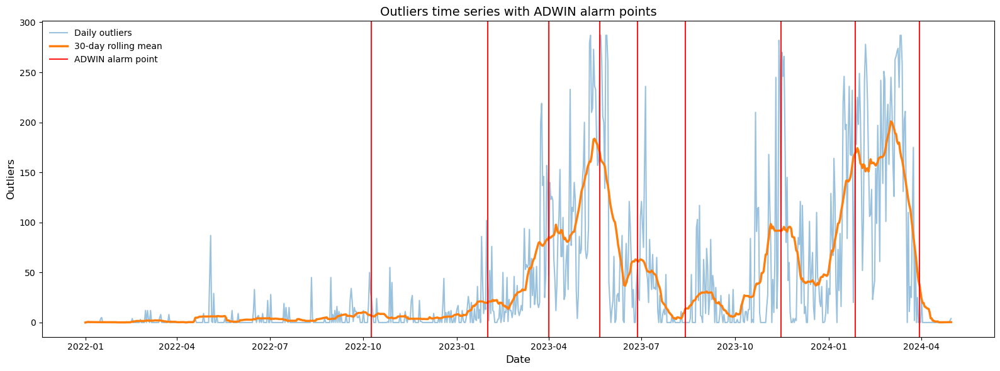

In [44]:
# ============================================================
#  SMOOTHED SERIES FOR VISUALIZATION
# ============================================================

outliers_by_day["rolling_mean_30d"] = (
    outliers_by_day["outliers"]
    .rolling(
        window=30,
        center=True,
        min_periods=1
    )
    .mean()
)

import matplotlib.pyplot as plt
import matplotlib.dates as mdates


# ============================================================
#  PLOT
# ============================================================

fig, ax = plt.subplots(figsize=(16, 6))


# ------------------------------------------------------------
# Raw daily observations
# ------------------------------------------------------------

ax.plot(
    outliers_by_day["date"],
    outliers_by_day["outliers"],
    color="tab:blue",
    alpha=0.45,
    linewidth=1.5,
    label="Daily outliers"
)


# ------------------------------------------------------------
# 30-day smoothed tendency
# ------------------------------------------------------------

ax.plot(
    outliers_by_day["date"],
    outliers_by_day["rolling_mean_30d"],
    color="tab:orange",
    linewidth=2.5,
    label="30-day rolling mean"
)


# ------------------------------------------------------------
# ADWIN estimated change points
# ------------------------------------------------------------

change_dates = pd.to_datetime(
    change_points["alarm_date"]
)

for j, change_date in enumerate(change_dates):

    ax.axvline(
        x=change_date,
        color="red",
        linewidth=1.5,
        alpha=0.9,
        label="ADWIN alarm point" if j == 0 else None
    )


# ------------------------------------------------------------
# Formatting
# ------------------------------------------------------------

ax.set_xlabel("Date", fontsize=12)
ax.set_ylabel("Outliers", fontsize=12)

ax.set_title(
    "Outliers time series with ADWIN alarm points",
    fontsize=14
)

ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=3)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y-%m")
)

plt.xticks(rotation=0)

ax.legend(frameon=False)

plt.tight_layout()

"""
plt.savefig(
    "outliers_ADWIN_change_points.png",
    dpi=300,
    bbox_inches="tight"
)
"""

plt.show()

#### Create new groups for the outliers before the cutday

In [45]:
cut_day = "2023-04-01"

In [ ]:
buffer = clustering_data_all[(clustering_data_all['timestamp'] =< cut_day) & clustering_data_all['outliers']].copy()[
    [
        'energy_mobile_mean',
        'kurtosis_mobile_mean',
        'frequency_index_mobile_mean',
        'entropy_mobile_mean'
    ]
]

# Scale variables
X_buffer = scaler.transform(buffer)
# Transform the data to the new reducted space
Z_buffer = pca.transform(X_buffer)

print(f"Outliers en buffer: {len(buffer)}")

Outliers en buffer: 4166


c:\Users\javie\miniconda3\envs\estancia_popocatepetl\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [47]:
# Trata con differentes valores para k
inertia = []
silh = []
k_s = np.arange(2, 10)
for k in k_s:
  km_model_aux = KMeans(n_clusters=k).fit(Z_buffer)
  inertia.append(km_model_aux.inertia_)
  silh.append(silhouette_score(Z_buffer, km_model_aux.labels_))

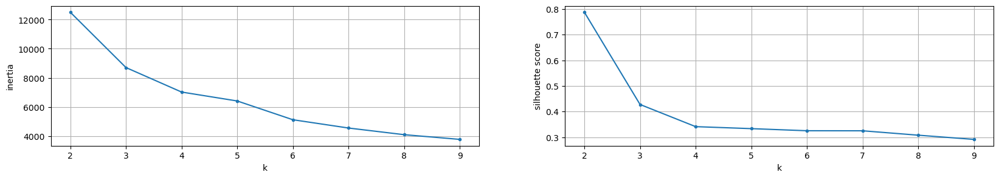

In [33]:
# Plot results
plt.figure(figsize=(20, 3))
plt.subplot(1, 2, 1)
plt.plot(k_s, inertia, '.-')
plt.grid()
plt.xlabel('k')
plt.ylabel('inertia')
plt.subplot(1, 2, 2)
plt.plot(k_s, silh, '.-')
plt.grid()
plt.xlabel('k')
plt.ylabel('silhouette score')
plt.show()

In [48]:
km_model_buffer = KMeans(n_clusters=3, random_state=9972, n_init=10).fit(Z_buffer)

len(km_model_buffer.cluster_centers_)

3

In [49]:
# Create a dataframe with the clustering data
clustering_data_buffer = pd.DataFrame(Z_buffer, columns= ['PC1', 'PC2', 'PC3'])
clustering_data_buffer['labels'] = km_model_buffer.labels_
# Create a dataframe with the clustering data


In [50]:
clustering_data_buffer[['labels','PC1']].groupby('labels').count()

,PC1
labels,
0,998
1,408
2,2760


In [51]:
MIN_MIEMBROS = 20   # ajusta según lo que viste arriba

n_original = len(km_model.cluster_centers_)
promover = []   # índices del buffer que sí se promueven

for k in range(km_model_buffer.n_clusters):
    n = (km_model_buffer.labels_ == k).sum()
    if n >= MIN_MIEMBROS:
        promover.append(k)
        print(f"✓ Buffer {k} ({n} miembros) → será Cluster {n_original + len(promover) - 1}")
    else:
        print(f"✗ Buffer {k} ({n} miembros) → descartado, queda como anomalía")

✓ Buffer 0 (998 miembros) → será Cluster 3
✓ Buffer 1 (408 miembros) → será Cluster 4
✓ Buffer 2 (2760 miembros) → será Cluster 5


In [52]:
mapping = {}   # {label_buffer: label_global}
for i, k in enumerate(promover):
    mapping[k] = n_original + i

print("Mapeo buffer → global:", mapping)

Mapeo buffer → global: {0: 3, 1: 4, 2: 5}


In [53]:
nuevos_centroides = km_model_buffer.cluster_centers_[promover]

centroides_expandidos = np.vstack([
    km_model.cluster_centers_,
    nuevos_centroides
])

print(f"Centroides: {n_original} → {len(centroides_expandidos)}")

Centroides: 3 → 6


In [54]:
buffer_labels_globales = np.array([
    mapping.get(lbl, -1) for lbl in km_model_buffer.labels_
])

buffer['labels_nuevo'] = buffer_labels_globales

print(pd.Series(buffer_labels_globales).value_counts().sort_index())

3     998
4     408
5    2760
Name: count, dtype: int64


#### Changing the labels

In [55]:
past_data_df = clustering_data_all[(clustering_data_all['timestamp'] < cut_day)]

In [56]:
# Initialize with the original labels
past_data_df['labels_final'] = past_data_df['labels']

# Overwrite only the rows of the buffer using the index
past_data_df['labels_final'] = past_data_df['labels'].astype(np.int64)
past_data_df.loc[buffer.index, 'labels_final'] = buffer['labels_nuevo'].to_numpy().astype(np.int64)

# Tag the points that still are outliers
past_data_df['outliers_final'] = past_data_df['labels_final'] == -1

In [45]:
past_data_df

,timestamp,energy_mobile_mean,kurtosis_mobile_mean,frequency_index_mobile_mean,entropy_mobile_mean,labels,distance_to_centroid,outliers,date,labels_final,outliers_final
10,2022-01-01 00:55:00,7.189824,1.016756,0.002807,6566.963119,1,1.206069,False,2022-01-01,1,False
11,2022-01-01 01:00:00,7.202035,1.135282,0.040282,6541.763823,1,1.238339,False,2022-01-01,1,False
12,2022-01-01 01:05:00,7.217582,1.225977,0.087732,6484.417105,1,1.376893,False,2022-01-01,1,False
13,2022-01-01 01:10:00,7.214921,1.221882,0.091360,6501.124913,1,1.392648,False,2022-01-01,1,False
14,2022-01-01 01:15:00,7.209869,1.217271,0.082832,6542.602102,1,1.389105,False,2022-01-01,1,False
...,...,...,...,...,...,...,...,...,...,...,...
130580,2023-03-31 23:35:00,9.146251,0.849162,-0.090320,1160.471966,2,3.077222,False,2023-03-31,2,False
130581,2023-03-31 23:40:00,9.172135,0.862607,-0.089538,1116.042890,2,3.107235,False,2023-03-31,2,False
130582,2023-03-31 23:45:00,9.178816,0.864605,-0.088342,1094.877941,2,3.115103,False,2023-03-31,2,False
130583,2023-03-31 23:50:00,9.180147,0.866773,-0.084943,1091.316726,2,3.102413,False,2023-03-31,2,False


In [57]:
n_before = past_data_df['outliers'].sum()
n_after = past_data_df['outliers_final'].sum()

print(f"Outliers antes:   {n_before}")
print(f"Outliers después: {n_after}")
print(f"Absorbidos:       {n_before - n_after}\n")

print(past_data_df['labels_final'].value_counts().sort_index())

Outliers antes:   4166
Outliers después: 0
Absorbidos:       4166

labels_final
0    66872
1    22529
2    33480
3      998
4      408
5     2760
Name: count, dtype: int64


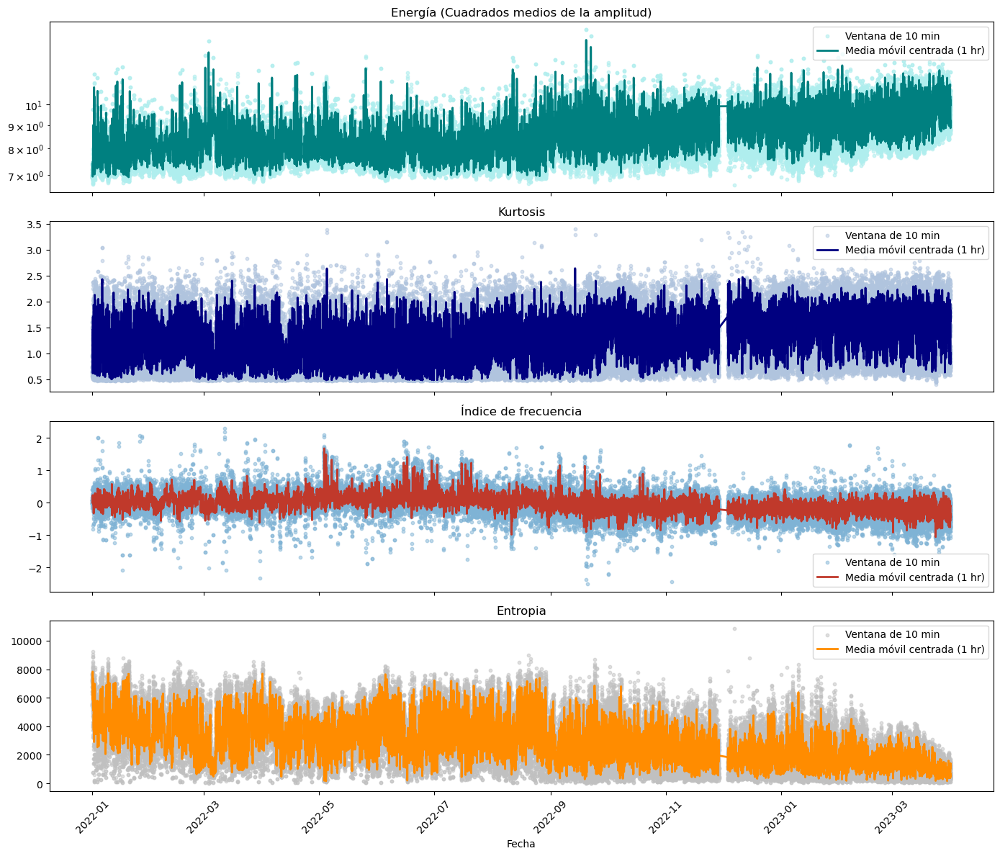

In [60]:
# Select the period of interes
features_df = features_df[features_df['timestamp']<cut_day]
# Generate the plot
fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(14, 12), sharex=True)
axes[0].scatter(features_df['timestamp'], features_df['energy'], color='paleturquoise', s=10, alpha=0.6, label="Ventana de 10 min")
axes[0].plot(features_df['timestamp'], features_df['energy_mobile_mean'], color='teal', linewidth=2, label='Media móvil centrada (1 hr)')
axes[0].set_yscale('log')
axes[0].set_title('Energía (Cuadrados medios de la amplitud)')
axes[0].legend(loc='best')

axes[1].scatter(features_df['timestamp'], features_df['kurtosis'], color='lightsteelblue', s=10, alpha=0.5, label = "Ventana de 10 min")
axes[1].plot(features_df['timestamp'], features_df['kurtosis_mobile_mean'], color='navy', alpha = 1,linewidth=2, label='Media móvil centrada (1 hr)')
axes[1].set_title('Kurtosis')
axes[1].legend(loc='best')

axes[2].scatter(features_df['timestamp'], features_df['frequency_index'], color='#7FB3D5', s=10, alpha=0.5, label = "Ventana de 10 min")
axes[2].plot(features_df['timestamp'], features_df['frequency_index_mobile_mean'], color='#C0392B', alpha = 1,linewidth=2, label='Media móvil centrada (1 hr)')
axes[2].set_title('Índice de frecuencia')
axes[2].legend(loc='best')

axes[3].scatter(features_df['timestamp'], features_df['entropy'], color='silver', s=10, alpha=0.5, label = "Ventana de 10 min")
axes[3].plot(features_df['timestamp'], features_df['entropy_mobile_mean'], color='darkorange', alpha = 1,linewidth=2, label='Media móvil centrada (1 hr)')
axes[3].set_title('Entropia')
axes[3].set_xlabel('Fecha')
axes[3].legend(loc='best')

plt.xticks(rotation=45)
plt.tight_layout()

In [67]:
# Filter the first eleven observations with NAs values
features_df = features_df.dropna(subset=['energy_mobile_mean'])
X = features_df[
    [
        'energy_mobile_mean',
        'kurtosis_mobile_mean',
        'frequency_index_mobile_mean',
        'entropy_mobile_mean'
    ]
]
# Scale variables
X = scaler.transform(X)
# Transform the data to the new reducted space
Z = pca.transform(X)

c:\Users\javie\miniconda3\envs\estancia_popocatepetl\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [69]:
labels

array([1, 1, 1, ..., 2, 2, 2], shape=(8883,), dtype=int32)

C:\Users\javie\AppData\Local\Temp\ipykernel_18332\3636200424.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


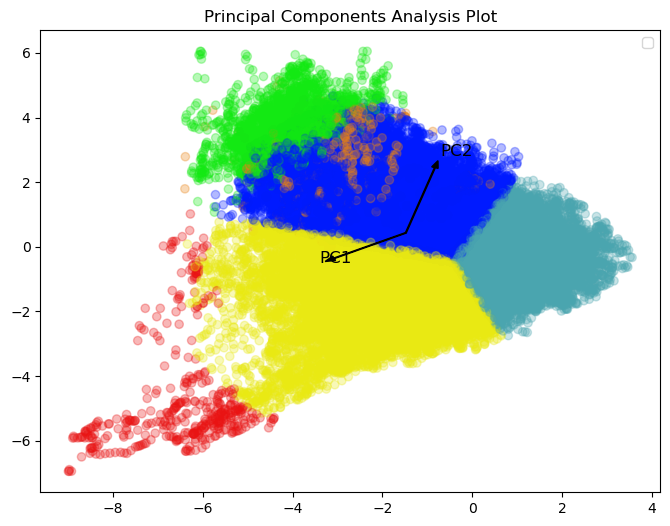

In [71]:
labels = past_data_df['labels_final']
custom_cmap = ListedColormap(["#001AFF", "#4aa5af", "#e9e913", "#e98213", "#e91313", "#13e913"])

plt.figure(figsize=(8, 6))
scatter = plt.scatter(Z[:, 0], Z[:, 1], c=labels, cmap=custom_cmap, alpha=0.3)
#plt.scatter(centroids[:, 0], centroids[:, 1], c='red', s=200, marker='+')
# Plot principal component axes
origin = np.mean(Z[:, :2], axis=0)
for i, (vec, var) in enumerate(zip(pca.components_[:2], pca.explained_variance_ratio_[:2])):
    plt.arrow(origin[0], origin[1], vec[0]*3, vec[1]*3, color='black', width=0.02, head_width=0.15, length_includes_head=True)
    plt.text(origin[0] + vec[0]*3.2, origin[1] + vec[1]*3.2, f'PC{i+1}', color='black', fontsize=12)
plt.title('Principal Components Analysis Plot')
plt.legend()
plt.show()

c:\Users\javie\miniconda3\envs\estancia_popocatepetl\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


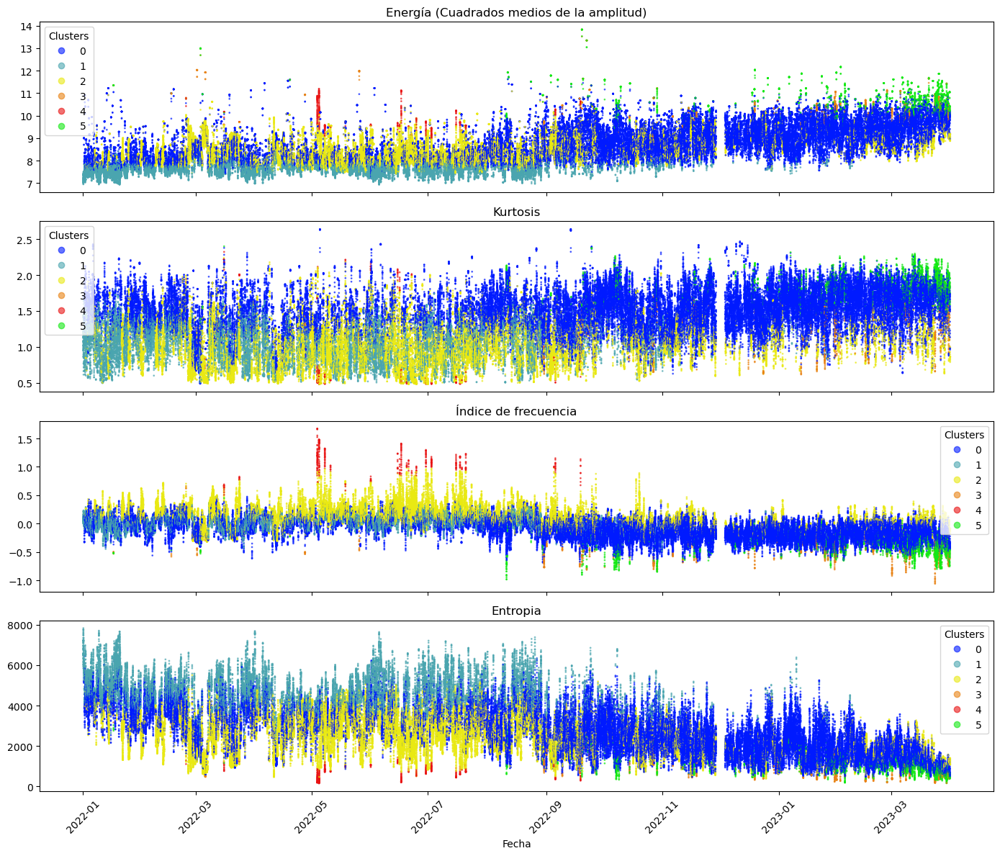

In [72]:
fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(14, 12), sharex=True)
scatter = axes[0].scatter(past_data_df['timestamp'], past_data_df['energy_mobile_mean'], c=past_data_df['labels_final'], cmap=custom_cmap, s=1, alpha=0.6)
axes[0].set_title('Energía (Cuadrados medios de la amplitud)')
axes[0].legend(*scatter.legend_elements(), title="Clusters")

scatter = axes[1].scatter(past_data_df['timestamp'], past_data_df['kurtosis_mobile_mean'], c=past_data_df['labels_final'], cmap=custom_cmap, s=1, alpha=0.6)
axes[1].set_title('Kurtosis')
axes[1].legend(*scatter.legend_elements(), title="Clusters")

scatter = axes[2].scatter(past_data_df['timestamp'], past_data_df['frequency_index_mobile_mean'], c=past_data_df['labels_final'], cmap=custom_cmap, s=1, alpha=0.6)
axes[2].set_title('Índice de frecuencia')
axes[2].legend(*scatter.legend_elements(), title="Clusters")

scatter = axes[3].scatter(past_data_df['timestamp'], past_data_df['entropy_mobile_mean'], c=past_data_df['labels_final'], cmap=custom_cmap, s=1, alpha=0.6)
axes[3].set_title('Entropia')
axes[3].set_xlabel('Fecha')
axes[3].legend(*scatter.legend_elements(), title="Clusters")



plt.xticks(rotation=45)
plt.tight_layout()

In [ ]:
past_data_df['day'] = pd.to_datetime(past_data_df['timestamp']).dt.date
# Group by day and take the first mode
daily_predominant_df = (
    past_data_df.groupby('day')["labels"]
    .agg(lambda x: x.mode().iat[0])
    .reset_index(name="label")
)

palette = {0:"#001AFF", 1:"#4aa5af", 2:"#e9e913", 3:"#e98213", 4:"#e91313", 5:"#13e913"}

# 2. Plot horizontal blocks (width = 1 day per row)
fig, ax = plt.subplots(figsize=(9, 6))

bar_colors = daily_predominant_df["label"].map(palette)


In [86]:
def plot_monthly_status(
    df: pd.DataFrame,
    target_month: str,  # Format: 'YYYY-MM', e.g., '2022-02'
    palette: dict,
    ax=None,
):
    """Plots daily status bars for a selected month."""
    # Ensure datetime format and filter to the selected month
    df = df.copy()
    df["dt"] = pd.to_datetime(df["day"])
    monthly_df = (
        df[df["dt"].dt.to_period("M") == target_month]
        .sort_values("dt")
        .reset_index(drop=True)
    )

    if monthly_df.empty:
        raise ValueError(f"No records found for month: {target_month}")

    # Map colors directly on the filtered month's rows
    bar_colors = monthly_df["label"].map(palette).fillna("#CCCCCC")

    # Initialize ax if not provided
    if ax is None:
        fig, ax = plt.subplots(figsize=(9, max(4, len(monthly_df) * 0.25)))

    # Use string representations for tick placement to ensure discrete bars
    y_labels = monthly_df["dt"].dt.strftime("%d (%a)")
    y_positions = range(len(monthly_df))

    # Plot horizontal bars
    ax.barh(
        y=y_positions,
        width=1,
        color=bar_colors,
        edgecolor="white",
        linewidth=0.5,
        height=0.8,
    )

    # Axis formatting
    ax.invert_yaxis()  # Day 1 starts at top
    ax.set_yticks(list(y_positions))
    ax.set_yticklabels(y_labels)

    ax.set_xlabel("Status Active (1 unit = 1 day)")
    ax.set_title(f"Daily Status Progression - {target_month}")
    ax.set_xlim(0, 1.2)
    ax.set_xticks([])  # Hide x-axis ticks

    # Legend
    patches = [
        mpatches.Patch(color=color, label=f"Status {name}")
        for name, color in palette.items()
    ]
    ax.legend(
        handles=patches,
        title="Status",
        loc="lower right",
        frameon=True,
    )

    ax.figure.tight_layout()
    return ax


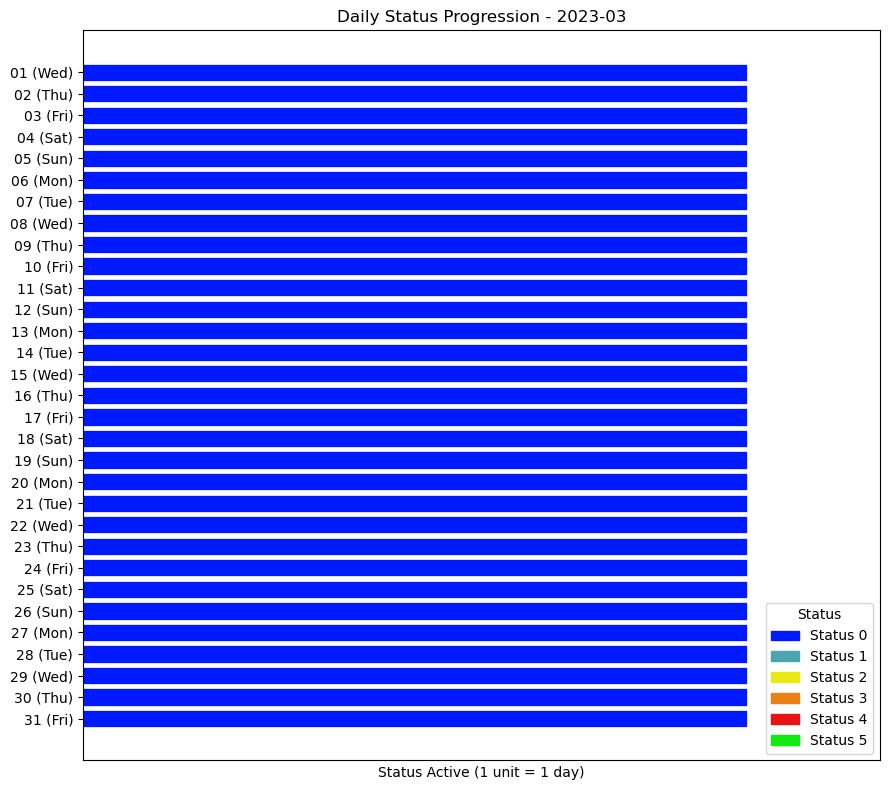

In [91]:
# Run plot
fig, ax = plt.subplots(figsize=(9, 8))
plot_monthly_status(
    df=daily_predominant_df,
    target_month="2023-03",
    palette=palette,
    ax=ax,
)
plt.show()

#### Retrain only for outliers

Apply the final model (original 3 centroids + 3 promoted from the buffer) to **all** the data after the cut day, check the distances and find the new outliers.

In [48]:
from sklearn.metrics import pairwise_distances

# Same cut as past_data_df, so there is no overlap
feature_cols = [
    'energy_mobile_mean',
    'kurtosis_mobile_mean',
    'frequency_index_mobile_mean',
    'entropy_mobile_mean'
]

post_df = clustering_data_all[clustering_data_all['timestamp'] >= cut_day][['timestamp'] + feature_cols].copy()

# Scale + PCA with the ORIGINAL scaler and pca
X_post = scaler.transform(post_df[feature_cols].to_numpy())
Z_post = pca.transform(X_post)

print(f"Observations after {cut_day}: {len(post_df)}")

Observations after 2023-04-01: 112968


In [49]:
# Distance to ALL the final centroids (original + promoted), keep the closest one
dist_post = pairwise_distances(Z_post, centroides_expandidos)

post_df['labels'] = dist_post.argmin(axis=1)
post_df['distance_to_centroid'] = dist_post.min(axis=1)
post_df['outliers'] = post_df['distance_to_centroid'] > 5

print(post_df['labels'].value_counts().sort_index())
print(f"\nOutliers (distance > 5): {post_df['outliers'].sum()}")

labels
0    24025
1     2777
2    29942
3    41489
4      547
5    14188
Name: count, dtype: int64

Outliers (distance > 5): 39


In [50]:
# Distance to ALL the final centroids (original + promoted), keep the closest one
dist_post = pairwise_distances(Z_post, centroides_expandidos)

post_df['labels'] = dist_post.argmin(axis=1)
post_df['distance_to_centroid'] = dist_post.min(axis=1)
#post_df['outliers'] = post_df['distance_to_centroid'] > 5

print(post_df['labels'].value_counts().sort_index())
#print(f"\nOutliers (distance > 5): {post_df['outliers'].sum()}")


# Cálculo de cuartiles y cota superior de valores
Q1 = post_df['distance_to_centroid'].quantile(0.25)
Q3 = post_df['distance_to_centroid'].quantile(0.75)
IQR = Q3 - Q1
upper_increment = Q3 + 1.5*IQR

print(f"Q1: {Q1:.3f} | Q3: {Q3:.3f} | IQR: {IQR:.3f}")
print(f"Cota superior (Q3 + 3*IQR): {upper_increment:.3f}")

# Redefinimos los outliers con la nueva cota
post_df['outliers'] = post_df['distance_to_centroid'] > upper_increment
print(f"Outliers: {post_df['outliers'].sum()} ({100*post_df['outliers'].mean():.2f}%)")


# Outliers defined as the distances above the 99th percentile
#PERCENTILE = 0.99
#upper_increment = post_df['distance_to_centroid'].quantile(PERCENTILE)

#print(f"Cota superior (percentil {PERCENTILE}): {upper_increment:.3f}")

#post_df['outliers'] = post_df['distance_to_centroid'] > upper_increment
#print(f"Outliers: {post_df['outliers'].sum()} ({100*post_df['outliers'].mean():.2f}%)")

labels
0    24025
1     2777
2    29942
3    41489
4      547
5    14188
Name: count, dtype: int64
Q1: 1.482 | Q3: 2.647 | IQR: 1.164
Cota superior (Q3 + 3*IQR): 4.393
Outliers: 276 (0.24%)


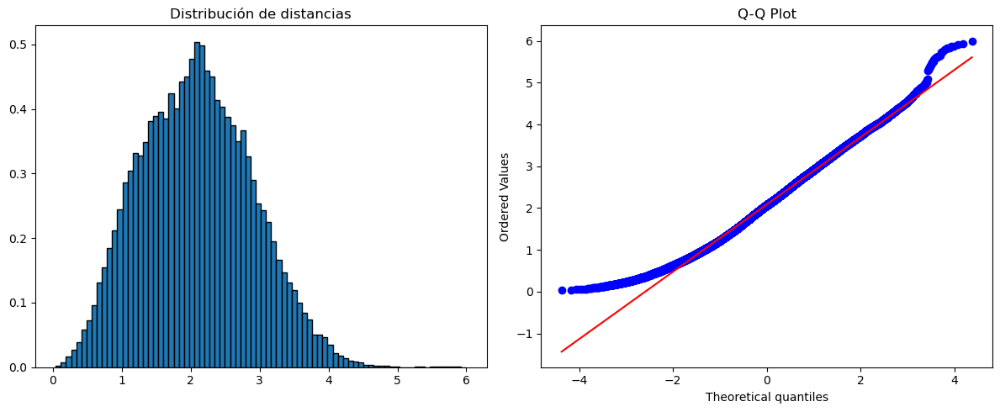

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Histogram
axes[0].hist(post_df['distance_to_centroid'], bins=80, density=True, edgecolor='black')
axes[0].set_title('Distribución de distancias')

# Q-Q plot
stats.probplot(post_df['distance_to_centroid'], plot=axes[1])
axes[1].set_title('Q-Q Plot')

plt.tight_layout()
plt.show()

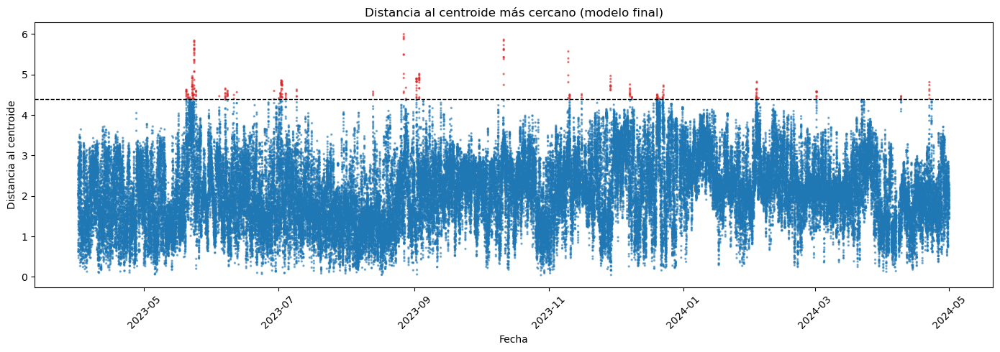

In [52]:
# Distance to the closest centroid over time
plt.figure(figsize=(14, 5))
plt.scatter(post_df['timestamp'], post_df['distance_to_centroid'],
            c=post_df['outliers'].map({False: '#1f77b4', True: '#d62728'}), s=2, alpha=0.5)
plt.axhline(upper_increment, color='k', linestyle='--', linewidth=1)
plt.xlabel('Fecha')
plt.ylabel('Distancia al centroide')
plt.title('Distancia al centroide más cercano (modelo final)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Daily outliers

In [53]:
post_df['date'] = pd.to_datetime(post_df['timestamp']).dt.date

total_by_day = post_df.groupby('date').size()
outliers_by_day = (post_df[post_df['outliers']]
                   .groupby('date')
                   .size())
# Reindex with all the days, filling with 0
outliers_by_day = outliers_by_day.reindex(total_by_day.index, fill_value=0)

outliers_by_day = outliers_by_day.reset_index()
outliers_by_day.columns = ['date', 'outliers']
outliers_by_day['total'] = total_by_day.values
outliers_by_day['outliers_pct'] = 100 * outliers_by_day['outliers'] / outliers_by_day['total']

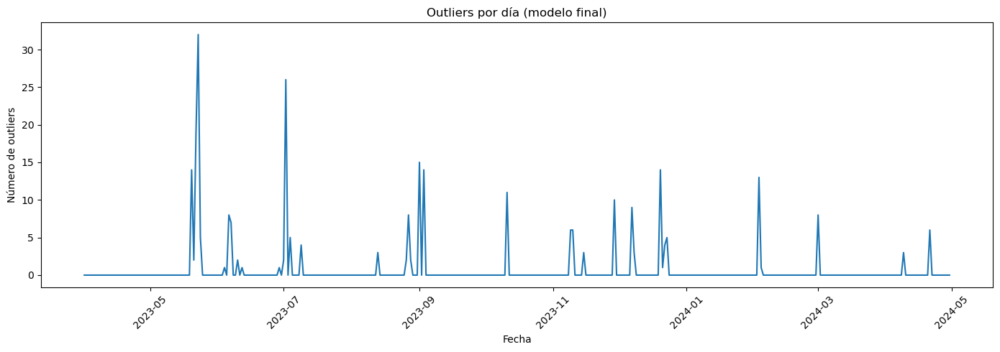

In [54]:
plt.figure(figsize=(14, 5))
plt.plot(outliers_by_day['date'], outliers_by_day['outliers'])
plt.xlabel('Fecha')
plt.ylabel('Número de outliers')
plt.title('Outliers por día (modelo final)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### When to retrain

In [61]:
outliers_by_day[outliers_by_day['outliers']>0]

,date,outliers,total,outliers_pct
49,2023-05-20,14,287,4.878049
50,2023-05-21,2,287,0.696864
51,2023-05-22,19,287,6.620209
52,2023-05-23,32,287,11.149826
53,2023-05-24,5,287,1.742160
64,2023-06-04,1,287,0.348432
66,2023-06-06,8,287,2.787456
67,2023-06-07,7,287,2.439024
70,2023-06-10,2,287,0.696864
72,2023-06-12,1,287,0.348432


In [60]:
# ============================================================
#  ONLINE CHANGE DETECTION
# ============================================================

alarms = []

for i, row in outliers_by_day.iterrows():

    value = row["outliers"]

    detector.update(value)

    if detector.drift_detected:

        # Date on which ADWIN has enough evidence to signal change
        alarm_date = row["date"]

        # Width is the size of ADWIN's retained window after
        # discarding observations belonging to the previous regime.
        #
        # Therefore, approximately:
        #
        # change_index = current_index - retained_window + 1
        #
        retained_window = int(detector.width)

        change_index = max(
            0,
            i - retained_window + 1
        )

        change_date = outliers_by_day.loc[change_index, "date"]

        alarms.append({
            "change_index": change_index,
            "change_date": change_date,
            "alarm_index": i,
            "alarm_date": alarm_date,
            "window_after_change": retained_window
        })


change_points = pd.DataFrame(alarms)

print(change_points)

Empty DataFrame
Columns: []
Index: []


El método no detectó cambios

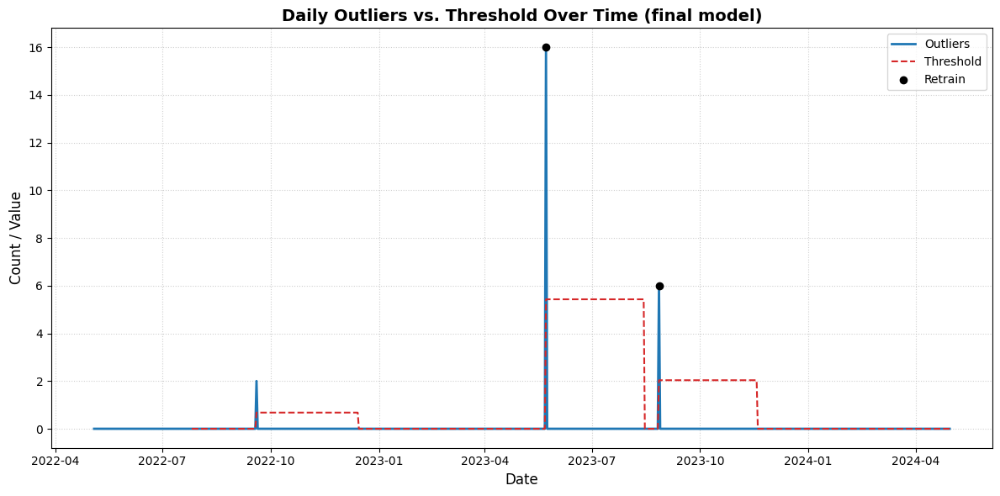

In [56]:
plt.figure(figsize=(12, 6))

plt.plot(outliers_by_day['date'], outliers_by_day["outliers"],
         label="Outliers", color="#1f77b4", linewidth=2)
plt.plot(outliers_by_day['date'], outliers_by_day["threshold"],
         label="Threshold", color="#d62728", linestyle="--", linewidth=1.5)

flagged = outliers_by_day[outliers_by_day['retrain']]
plt.scatter(flagged['date'], flagged['outliers'], color='k', zorder=3, label='Retrain')

plt.title("Daily Outliers vs. Threshold Over Time (final model)", fontsize=14, fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Count / Value", fontsize=12)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

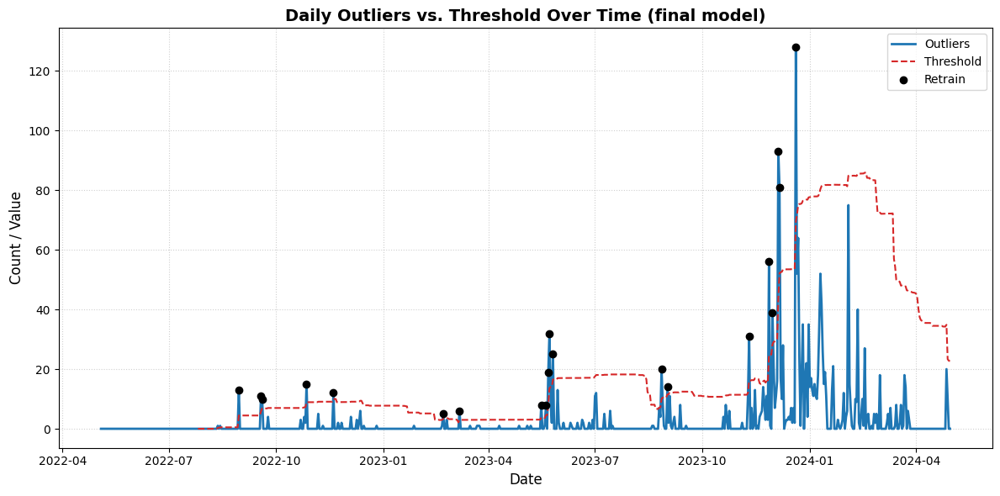

In [47]:
plt.figure(figsize=(12, 6))

plt.plot(outliers_by_day['date'], outliers_by_day["outliers"],
         label="Outliers", color="#1f77b4", linewidth=2)
plt.plot(outliers_by_day['date'], outliers_by_day["threshold"],
         label="Threshold", color="#d62728", linestyle="--", linewidth=1.5)

flagged = outliers_by_day[outliers_by_day['retrain']]
plt.scatter(flagged['date'], flagged['outliers'], color='k', zorder=3, label='Retrain')

plt.title("Daily Outliers vs. Threshold Over Time (final model)", fontsize=14, fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Count / Value", fontsize=12)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

In [57]:
outliers_by_day[outliers_by_day['retrain']]

,date,outliers,total,outliers_pct,mean_window,std_window,threshold,retrain
381,2023-05-23,16,287,5.574913,0.190476,1.745743,5.427706,True
477,2023-08-27,6,287,2.090592,0.071429,0.654654,2.035390,True


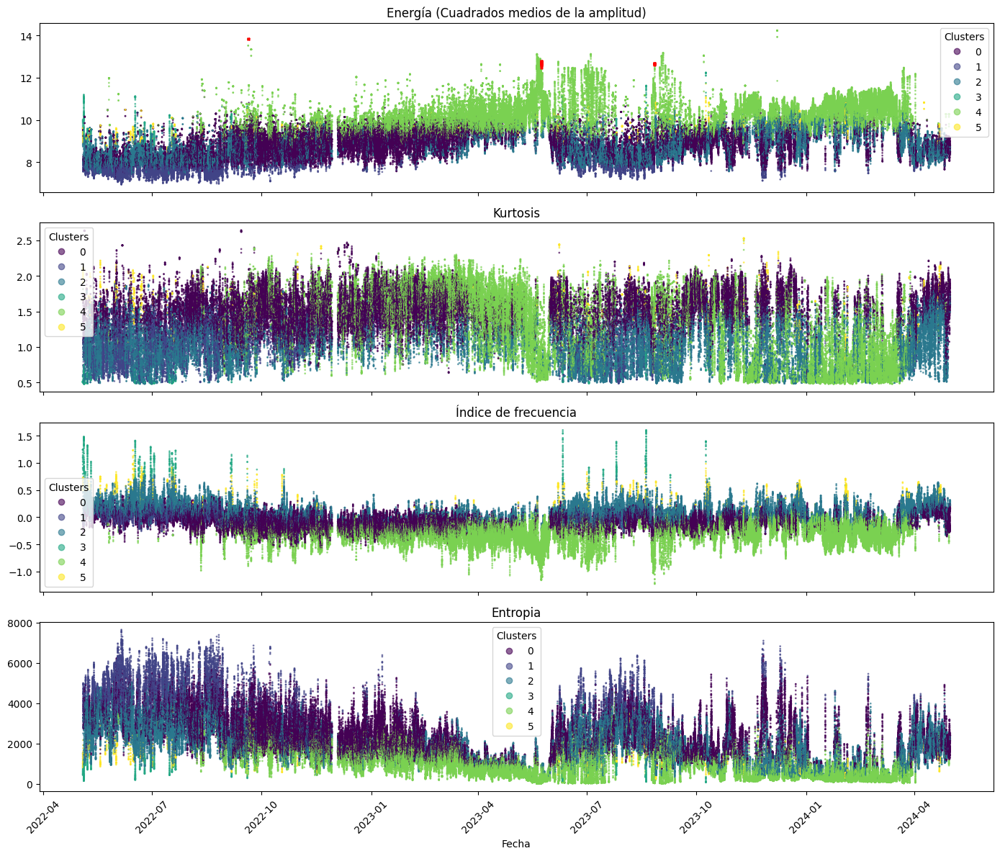

In [58]:
fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(14, 12), sharex=True)
scatter = axes[0].scatter(post_df['timestamp'], post_df['energy_mobile_mean'], c=post_df['labels'], cmap='viridis', vmin=0, vmax=5, s=1, alpha=0.6)
axes[0].set_title('Energía (Cuadrados medios de la amplitud)')
axes[0].legend(*scatter.legend_elements(), title="Clusters")

scatter = axes[1].scatter(post_df['timestamp'], post_df['kurtosis_mobile_mean'], c=post_df['labels'], cmap='viridis', vmin=0, vmax=5, s=1, alpha=0.6)
axes[1].set_title('Kurtosis')
axes[1].legend(*scatter.legend_elements(), title="Clusters")

scatter = axes[2].scatter(post_df['timestamp'], post_df['frequency_index_mobile_mean'], c=post_df['labels'], cmap='viridis', vmin=0, vmax=5, s=1, alpha=0.6)
axes[2].set_title('Índice de frecuencia')
axes[2].legend(*scatter.legend_elements(), title="Clusters")

scatter = axes[3].scatter(post_df['timestamp'], post_df['entropy_mobile_mean'], c=post_df['labels'], cmap='viridis', vmin=0, vmax=5, s=1, alpha=0.6)
axes[3].set_title('Entropia')
axes[3].set_xlabel('Fecha')
axes[3].legend(*scatter.legend_elements(), title="Clusters")

out = post_df[post_df['outliers']]
axes[0].scatter(out['timestamp'], out['energy_mobile_mean'], color='red', s=6, marker='x')

plt.xticks(rotation=45)
plt.tight_layout()

In [59]:
# First day that would trigger a new retraining
next_cut = outliers_by_day.loc[outliers_by_day['retrain'], 'date'].min()
print(f"Next retraining day: {next_cut}")

Next retraining day: 2023-05-23


## Iteration 2 – retrain at `next_cut`

#### Buffer: outliers between the first cut and the new cut day

In [60]:
# Same logic as iteration 1: the trigger day is included in the buffer
cut_day_2 = pd.Timestamp(next_cut) + pd.Timedelta(days=1)
ts_post = pd.to_datetime(post_df['timestamp'])

mask_buffer_2 = ((ts_post < cut_day_2) & post_df['outliers']).to_numpy()
buffer_2 = post_df[mask_buffer_2].copy()
Z_buffer_2 = Z_post[mask_buffer_2]          # already scaled + PCA, no need to transform again

print(f"Outliers en buffer 2: {len(buffer_2)}")
print(buffer_2.groupby('date').size())

Outliers en buffer 2: 18
date
2022-09-19     2
2023-05-23    16
dtype: int64


In [61]:
c_buffer = Z_buffer_2.mean(axis=0)
d_buffer = np.linalg.norm(Z_buffer_2 - c_buffer, axis=1)
print(pd.Series(d_buffer).describe())

count    18.000000
mean      0.725314
std       0.855853
min       0.335233
25%       0.414241
50%       0.443397
75%       0.488351
max       3.074158
dtype: float64


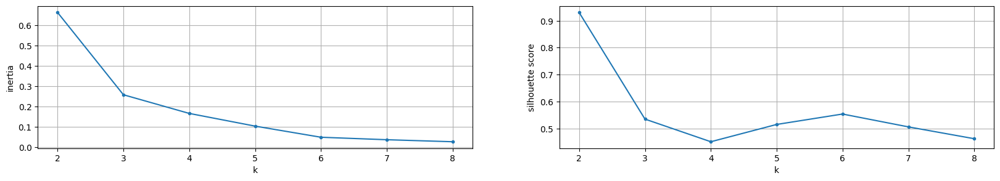

In [62]:
# Try different values of k (needs at least 3 points in the buffer)
inertia_2 = []
silh_2 = []
k_s_2 = np.arange(2, min(9, len(Z_buffer_2)))
for k in k_s_2:
    km_model_aux = KMeans(n_clusters=k, random_state=9972, n_init=10).fit(Z_buffer_2)
    inertia_2.append(km_model_aux.inertia_)
    silh_2.append(silhouette_score(Z_buffer_2, km_model_aux.labels_))

plt.figure(figsize=(20, 3))
plt.subplot(1, 2, 1)
plt.plot(k_s_2, inertia_2, '.-')
plt.grid()
plt.xlabel('k')
plt.ylabel('inertia')
plt.subplot(1, 2, 2)
plt.plot(k_s_2, silh_2, '.-')
plt.grid()
plt.xlabel('k')
plt.ylabel('silhouette score')
plt.show()

In [63]:
K_NEW = 2   # adjust after looking at the plots above
km_model_buffer_2 = KMeans(n_clusters=K_NEW, random_state=9972, n_init=10).fit(Z_buffer_2)

clustering_data_buffer_2 = pd.DataFrame(Z_buffer_2, columns=['PC1', 'PC2', 'PC3'])
clustering_data_buffer_2['labels'] = km_model_buffer_2.labels_
clustering_data_buffer_2[['labels', 'PC1']].groupby('labels').count()

,PC1
labels,
0,16
1,2


#### Promote the new groups

In [64]:
MIN_MIEMBROS_2 = 5   # the buffer is much smaller than in iteration 1 (134), so this needs to be lower; adjust

n_original_2 = len(centroides_expandidos)
promover_2 = []

for k in range(km_model_buffer_2.n_clusters):
    n = (km_model_buffer_2.labels_ == k).sum()
    if n >= MIN_MIEMBROS_2:
        promover_2.append(k)
        print(f"✓ Buffer {k} ({n} miembros) → será Cluster {n_original_2 + len(promover_2) - 1}")
    else:
        print(f"✗ Buffer {k} ({n} miembros) → descartado, queda como anomalía")

mapping_2 = {k: n_original_2 + i for i, k in enumerate(promover_2)}
print("Mapeo buffer → global:", mapping_2)

✓ Buffer 0 (16 miembros) → será Cluster 6
✗ Buffer 1 (2 miembros) → descartado, queda como anomalía
Mapeo buffer → global: {0: 6}


In [65]:
nuevos_centroides_2 = km_model_buffer_2.cluster_centers_[promover_2]

centroides_expandidos_2 = np.vstack([centroides_expandidos, nuevos_centroides_2])
print(f"Centroides: {n_original_2} → {len(centroides_expandidos_2)}")

buffer_labels_globales_2 = np.array([mapping_2.get(lbl, -1) for lbl in km_model_buffer_2.labels_])
buffer_2['labels_nuevo'] = buffer_labels_globales_2
print(pd.Series(buffer_labels_globales_2).value_counts().sort_index())

Centroides: 6 → 7
-1     2
 6    16
Name: count, dtype: int64


#### Changing the labels (between the first cut and the new cut)

In [66]:
past_data_df_2 = post_df[(ts_post < cut_day_2).to_numpy()].copy()

# Initialize with the labels of the first final model
past_data_df_2['labels_final'] = past_data_df_2['labels']

# Overwrite only the rows of the buffer using the index
past_data_df_2.loc[buffer_2.index, 'labels_final'] = buffer_2['labels_nuevo']

# Tag the points that still are outliers
past_data_df_2['outliers_final'] = past_data_df_2['labels_final'] == -1

print(f"Outliers antes:   {past_data_df_2['outliers'].sum()}")
print(f"Outliers después: {past_data_df_2['outliers_final'].sum()}\n")
print(past_data_df_2['labels_final'].value_counts().sort_index())

Outliers antes:   18
Outliers después: 2

labels_final
-1        2
 0    42884
 1    10532
 2    22869
 3      506
 4    30711
 5      609
 6       16
Name: count, dtype: int64


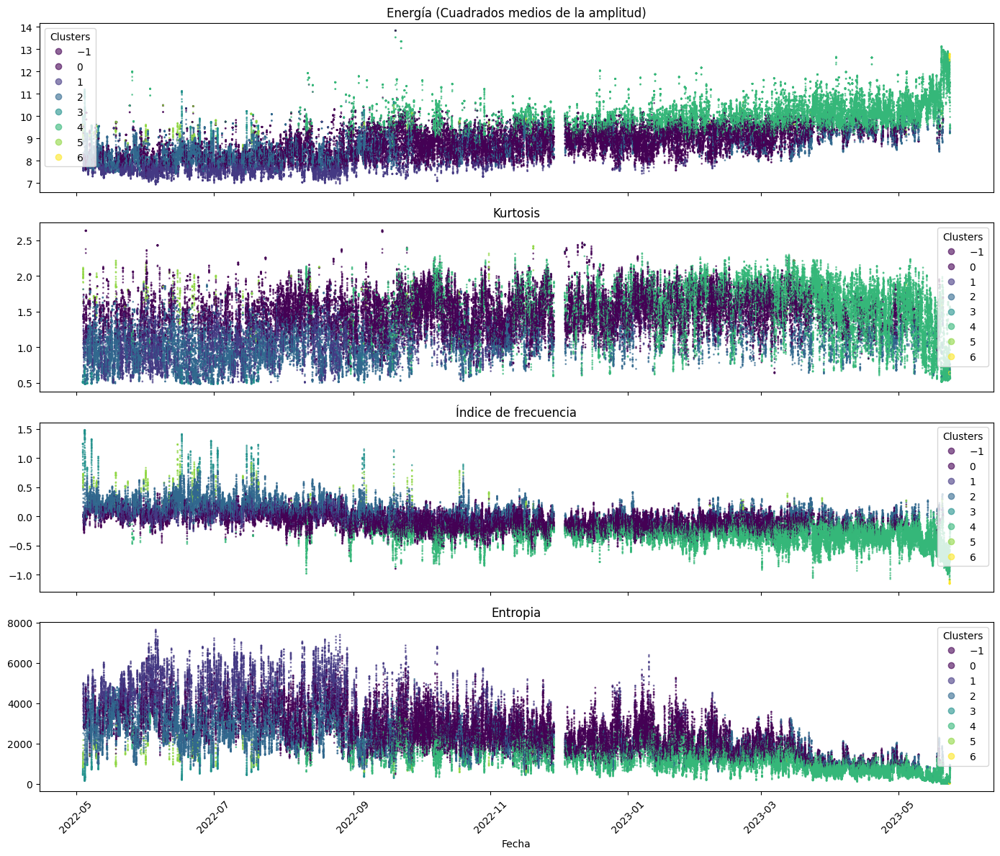

In [67]:
n_cl = len(centroides_expandidos_2)
panels = [('energy_mobile_mean', 'Energía (Cuadrados medios de la amplitud)'),
          ('kurtosis_mobile_mean', 'Kurtosis'),
          ('frequency_index_mobile_mean', 'Índice de frecuencia'),
          ('entropy_mobile_mean', 'Entropia')]

fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(14, 12), sharex=True)
for ax, (col, title) in zip(axes, panels):
    scatter = ax.scatter(past_data_df_2['timestamp'], past_data_df_2[col], c=past_data_df_2['labels_final'],
                         cmap='viridis', vmin=0, vmax=n_cl-1, s=1, alpha=0.6)
    ax.set_title(title)
    ax.legend(*scatter.legend_elements(), title="Clusters")
axes[3].set_xlabel('Fecha')

plt.xticks(rotation=45)
plt.tight_layout()

#### Apply the new model to all the data after the new cut day

In [68]:
mask_post_2 = (ts_post >= cut_day_2).to_numpy()
post_df_2 = post_df[mask_post_2][['timestamp'] + feature_cols].copy()
Z_post_2 = Z_post[mask_post_2]

print(f"Observations after {cut_day_2.date()}: {len(post_df_2)}")

dist_post_2 = pairwise_distances(Z_post_2, centroides_expandidos_2)
post_df_2['labels'] = dist_post_2.argmin(axis=1)
post_df_2['distance_to_centroid'] = dist_post_2.min(axis=1)
print(post_df_2['labels'].value_counts().sort_index())

# Outlier bound recomputed with the new distances (same multiplier as in iteration 1)
N_IQR = 1.5
Q1 = post_df_2['distance_to_centroid'].quantile(0.25)
Q3 = post_df_2['distance_to_centroid'].quantile(0.75)
IQR = Q3 - Q1
upper_increment_2 = Q3 + N_IQR*IQR

print(f"Q1: {Q1:.3f} | Q3: {Q3:.3f} | IQR: {IQR:.3f}")
print(f"Cota superior (Q3 + {N_IQR}*IQR): {upper_increment_2:.3f}")

post_df_2['outliers'] = post_df_2['distance_to_centroid'] > upper_increment_2
print(f"Outliers: {post_df_2['outliers'].sum()} ({100*post_df_2['outliers'].mean():.2f}%)")

Observations after 2023-05-24: 97757
labels
0    26182
1     2777
2    29870
3      231
4    37342
5      902
6      453
Name: count, dtype: int64
Q1: 1.607 | Q3: 2.892 | IQR: 1.286
Cota superior (Q3 + 1.5*IQR): 4.821
Outliers: 0 (0.00%)


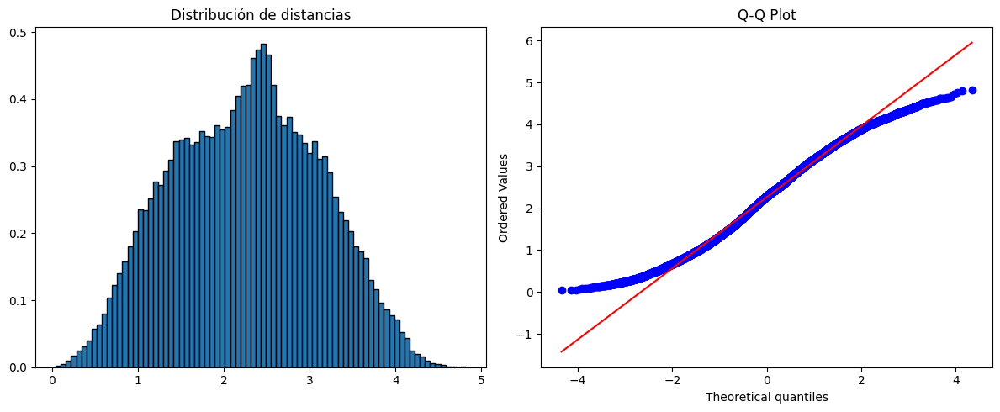

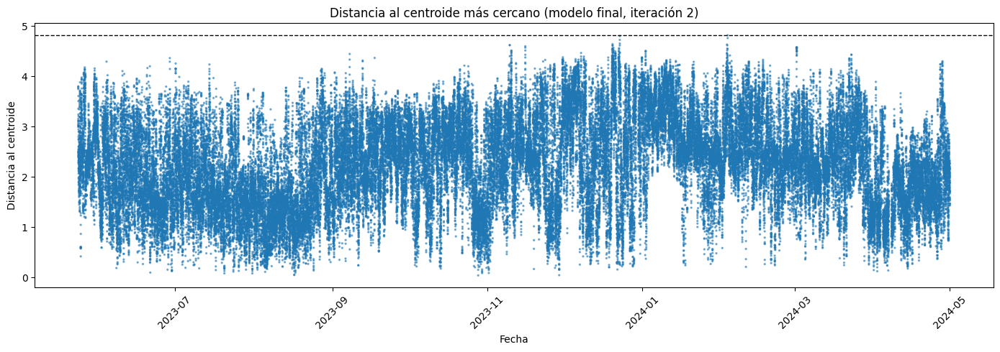

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].hist(post_df_2['distance_to_centroid'], bins=80, density=True, edgecolor='black')
axes[0].set_title('Distribución de distancias')
stats.probplot(post_df_2['distance_to_centroid'], plot=axes[1])
axes[1].set_title('Q-Q Plot')
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 5))
plt.scatter(post_df_2['timestamp'], post_df_2['distance_to_centroid'],
            c=post_df_2['outliers'].map({False: '#1f77b4', True: '#d62728'}), s=2, alpha=0.5)
plt.axhline(upper_increment_2, color='k', linestyle='--', linewidth=1)
plt.xlabel('Fecha')
plt.ylabel('Distancia al centroide')
plt.title('Distancia al centroide más cercano (modelo final, iteración 2)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Daily outliers and when to retrain

In [70]:
post_df_2['date'] = pd.to_datetime(post_df_2['timestamp']).dt.date

total_by_day = post_df_2.groupby('date').size()
outliers_by_day_2 = (post_df_2[post_df_2['outliers']].groupby('date').size())
outliers_by_day_2 = outliers_by_day_2.reindex(total_by_day.index, fill_value=0)

outliers_by_day_2 = outliers_by_day_2.reset_index()
outliers_by_day_2.columns = ['date', 'outliers']
outliers_by_day_2['total'] = total_by_day.values
outliers_by_day_2['outliers_pct'] = 100 * outliers_by_day_2['outliers'] / outliers_by_day_2['total']

# Same parameters as before (window_days, n_std, MIN_OUTLIERS_DAY).
# Note: the first window_days rows have no threshold, so a retrain can't be flagged before that.
outliers_by_day_2['mean_window'] = outliers_by_day_2['outliers'].rolling(window=window_days, center=False).mean()
outliers_by_day_2['std_window'] = outliers_by_day_2['outliers'].rolling(window=window_days, center=False).std()
outliers_by_day_2['threshold'] = outliers_by_day_2['mean_window'] + n_std*outliers_by_day_2['std_window']
outliers_by_day_2['retrain'] = (outliers_by_day_2['outliers'] > outliers_by_day_2['threshold']) & \
                               (outliers_by_day_2['outliers'] >= MIN_OUTLIERS_DAY)

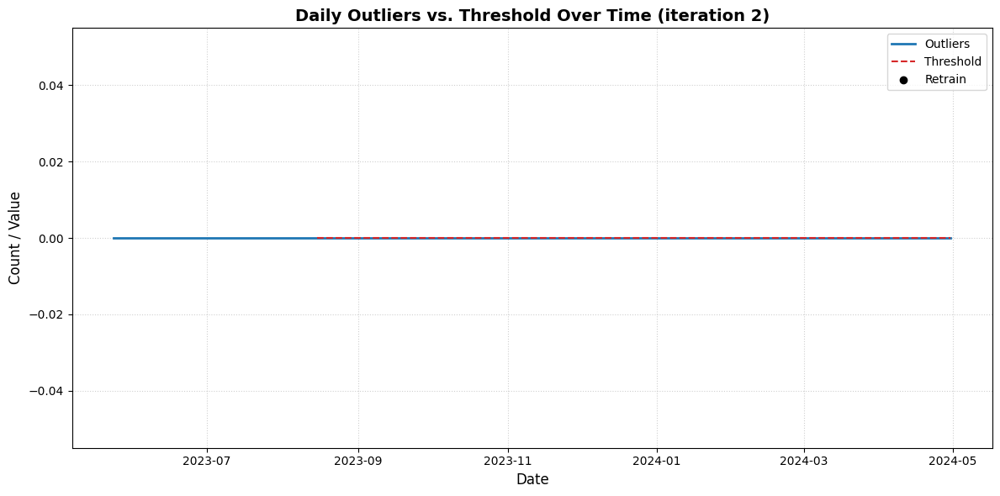

In [71]:
plt.figure(figsize=(12, 6))

plt.plot(outliers_by_day_2['date'], outliers_by_day_2["outliers"],
         label="Outliers", color="#1f77b4", linewidth=2)
plt.plot(outliers_by_day_2['date'], outliers_by_day_2["threshold"],
         label="Threshold", color="#d62728", linestyle="--", linewidth=1.5)

flagged_2 = outliers_by_day_2[outliers_by_day_2['retrain']]
plt.scatter(flagged_2['date'], flagged_2['outliers'], color='k', zorder=3, label='Retrain')

plt.title("Daily Outliers vs. Threshold Over Time (iteration 2)", fontsize=14, fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Count / Value", fontsize=12)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

In [72]:
outliers_by_day_2[outliers_by_day_2['retrain']]

,date,outliers,total,outliers_pct,mean_window,std_window,threshold,retrain


In [73]:
next_cut_2 = outliers_by_day_2.loc[outliers_by_day_2['retrain'], 'date'].min()
print(f"Next retraining day: {next_cut_2}")

Next retraining day: nan


In [74]:
all_df = clustering_data_all[['timestamp'] + feature_cols].copy()

X_all = scaler.transform(all_df[feature_cols].to_numpy())
Z_all = pca.transform(X_all)

dist_all = pairwise_distances(Z_all, centroides_expandidos_2)
all_df['labels'] = dist_all.argmin(axis=1)
all_df['distance_to_centroid'] = dist_all.min(axis=1)

print(f"Observations: {len(all_df)}")
print(all_df['labels'].value_counts().sort_index())

Observations: 240015
labels
0    79946
1    25306
2    62930
3      777
4    68172
5     1812
6     1072
Name: count, dtype: int64


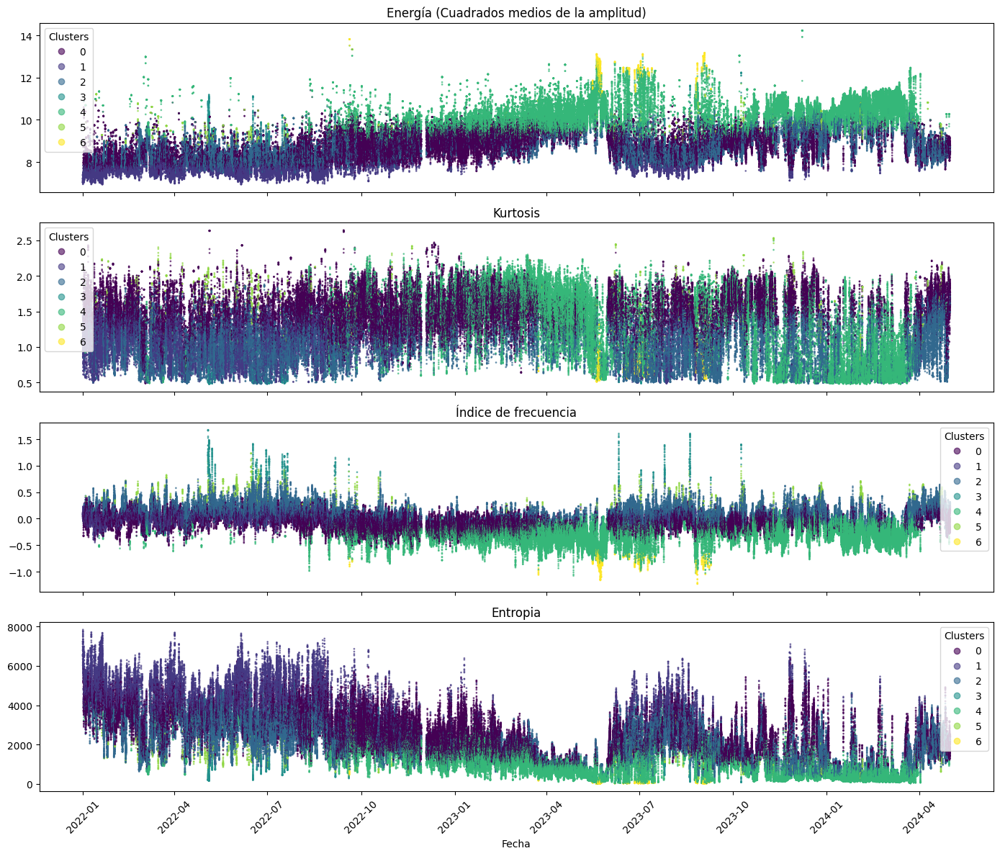

In [75]:
n_cl = len(centroides_expandidos_2)
panels = [('energy_mobile_mean', 'Energía (Cuadrados medios de la amplitud)'),
          ('kurtosis_mobile_mean', 'Kurtosis'),
          ('frequency_index_mobile_mean', 'Índice de frecuencia'),
          ('entropy_mobile_mean', 'Entropia')]

fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(14, 12), sharex=True)
for ax, (col, title) in zip(axes, panels):
    scatter = ax.scatter(all_df['timestamp'], all_df[col], c=all_df['labels'],
                         cmap='viridis', vmin=0, vmax=n_cl-1, s=1, alpha=0.6)
    ax.set_title(title)
    ax.legend(*scatter.legend_elements(), title="Clusters")
axes[3].set_xlabel('Fecha')

plt.xticks(rotation=45)
plt.tight_layout()

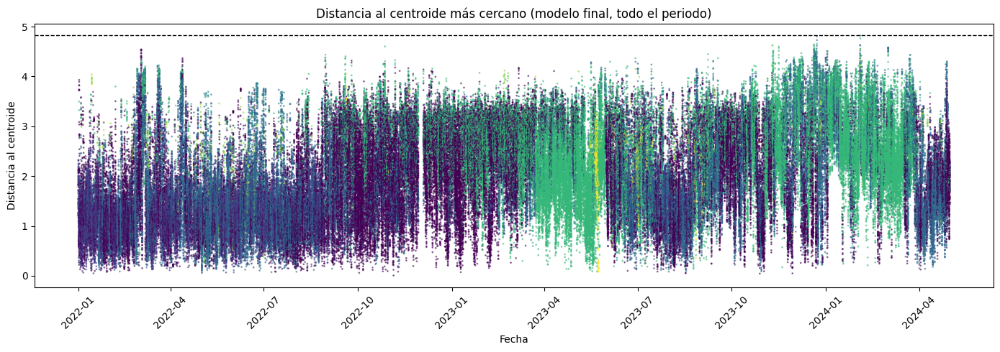

In [76]:
plt.figure(figsize=(14, 5))
plt.scatter(all_df['timestamp'], all_df['distance_to_centroid'], c=all_df['labels'],
            cmap='viridis', vmin=0, vmax=n_cl-1, s=1, alpha=0.5)
plt.axhline(upper_increment_2, color='k', linestyle='--', linewidth=1)
plt.xlabel('Fecha')
plt.ylabel('Distancia al centroide')
plt.title('Distancia al centroide más cercano (modelo final, todo el periodo)')
plt.xticks(rotation=45)
plt.tight_layout()